In [1]:
from pathlib import Path
import sys
import platform
import pandas as pd

# =========================================================
# AthletiQ — SoccerNet Ball Dataset Preparation
# Continuation Notebook
# =========================================================

NOTEBOOK_DIR = Path.cwd()

# ai-engine/notebooks -> AthletiQ
PROJECT_ROOT = NOTEBOOK_DIR.parent.parent

SOCCERNET_ROOT = (
    PROJECT_ROOT
    / "datasets"
    / "football"
    / "benchmarks"
    / "soccernet"
    / "tracking"
)

OUTPUT_ROOT = (
    PROJECT_ROOT
    / "datasets"
    / "football"
    / "processed"
    / "soccernet_ball_yolo"
)

MODEL_PATH = (
    PROJECT_ROOT
    / "ai-engine"
    / "models"
    / "football_ball_detector.pt"
)

print("Notebook directory :", NOTEBOOK_DIR)
print("Project root       :", PROJECT_ROOT)
print("SoccerNet root     :", SOCCERNET_ROOT)
print("Output root        :", OUTPUT_ROOT)
print("Model path         :", MODEL_PATH)

Notebook directory : /mnt/d/My Projects/AthletiQ/AthletiQ/ai-engine/notebooks
Project root       : /mnt/d/My Projects/AthletiQ/AthletiQ
SoccerNet root     : /mnt/d/My Projects/AthletiQ/AthletiQ/datasets/football/benchmarks/soccernet/tracking
Output root        : /mnt/d/My Projects/AthletiQ/AthletiQ/datasets/football/processed/soccernet_ball_yolo
Model path         : /mnt/d/My Projects/AthletiQ/AthletiQ/ai-engine/models/football_ball_detector.pt


In [2]:
from collections import Counter

print("=" * 60)
print("CHECKING PREVIOUS CONVERSION")
print("=" * 60)

for split in ["train", "val", "test"]:
    
    img_dir = OUTPUT_ROOT / "images" / split
    lbl_dir = OUTPUT_ROOT / "labels" / split
    
    images = list(img_dir.glob("*.jpg")) if img_dir.exists() else []
    labels = list(lbl_dir.glob("*.txt")) if lbl_dir.exists() else []
    
    # Sequence name is everything before the final "_000001.jpg"
    sequences = Counter(
        p.stem.rsplit("_", 1)[0]
        for p in images
    )
    
    complete = {
        seq: count
        for seq, count in sequences.items()
        if count == 750
    }
    
    incomplete = {
        seq: count
        for seq, count in sequences.items()
        if count != 750
    }
    
    print()
    print(f"{split.upper()}")
    print("-" * 60)
    print(f"Images              : {len(images):,}")
    print(f"Labels              : {len(labels):,}")
    print(f"Sequences found     : {len(sequences)}")
    print(f"Complete sequences  : {len(complete)}")
    print(f"Incomplete sequences: {len(incomplete)}")
    
    if incomplete:
        print("\nIncomplete sequences:")
        for seq, count in sorted(incomplete.items()):
            print(f"  {seq}: {count} images")
    
    if sequences:
        print("\nLast 5 sequences found:")
        for seq, count in sorted(sequences.items())[-5:]:
            print(f"  {seq}: {count} images")

print()
print("=" * 60)
print("CHECK COMPLETE")
print("=" * 60)

CHECKING PREVIOUS CONVERSION

TRAIN
------------------------------------------------------------
Images              : 55,500
Labels              : 55,500
Sequences found     : 74
Complete sequences  : 74
Incomplete sequences: 0

Last 5 sequences found:
  SNMOT-196: 750 images
  SNMOT-197: 750 images
  SNMOT-198: 750 images
  SNMOT-199: 750 images
  SNMOT-200: 750 images

VAL
------------------------------------------------------------
Images              : 11,250
Labels              : 11,250
Sequences found     : 15
Complete sequences  : 15
Incomplete sequences: 0

Last 5 sequences found:
  SNMOT-157: 750 images
  SNMOT-158: 750 images
  SNMOT-164: 750 images
  SNMOT-166: 750 images
  SNMOT-168: 750 images

TEST
------------------------------------------------------------
Images              : 12,750
Labels              : 12,750
Sequences found     : 17
Complete sequences  : 17
Incomplete sequences: 0

Last 5 sequences found:
  SNMOT-151: 750 images
  SNMOT-159: 750 images
  SNMOT-162

In [3]:
# =========================================================
# Cell 3 — Count converted YOLO ball annotations
# =========================================================

total_boxes = 0
empty_labels = 0
nonempty_labels = 0
invalid_lines = 0

split_stats = {}

for split in ["train", "val", "test"]:
    
    label_dir = OUTPUT_ROOT / "labels" / split
    
    boxes = 0
    empty = 0
    nonempty = 0
    invalid = 0
    
    for label_path in label_dir.glob("*.txt"):
        
        lines = [
            line.strip()
            for line in label_path.read_text().splitlines()
            if line.strip()
        ]
        
        if not lines:
            empty += 1
            continue
        
        nonempty += 1
        
        for line in lines:
            
            parts = line.split()
            
            if len(parts) != 5:
                invalid += 1
                continue
            
            try:
                class_id = int(parts[0])
                values = [float(x) for x in parts[1:]]
            except ValueError:
                invalid += 1
                continue
            
            # Expected: class 0 and normalized values
            if class_id != 0 or not all(0 <= v <= 1 for v in values):
                invalid += 1
                continue
            
            boxes += 1
    
    split_stats[split] = {
        "boxes": boxes,
        "empty_labels": empty,
        "nonempty_labels": nonempty,
        "invalid_lines": invalid,
    }
    
    total_boxes += boxes
    empty_labels += empty
    nonempty_labels += nonempty
    invalid_lines += invalid

print("=" * 60)
print("CONVERTED YOLO ANNOTATION CHECK")
print("=" * 60)

for split, stats in split_stats.items():
    print(f"\n{split.upper()}")
    print("-" * 40)
    print(f"Ball boxes       : {stats['boxes']:,}")
    print(f"Empty labels     : {stats['empty_labels']:,}")
    print(f"Non-empty labels : {stats['nonempty_labels']:,}")
    print(f"Invalid lines    : {stats['invalid_lines']:,}")

print("\n" + "=" * 60)
print("TOTAL")
print("=" * 60)
print(f"Ball boxes       : {total_boxes:,}")
print(f"Empty labels     : {empty_labels:,}")
print(f"Non-empty labels : {nonempty_labels:,}")
print(f"Invalid lines    : {invalid_lines:,}")

print("\nExpected ball boxes: 75,060")

if total_boxes == 75060 and invalid_lines == 0:
    print("✅ ANNOTATION CONVERSION VERIFIED")
else:
    print("⚠️ CHECK REQUIRED")

CONVERTED YOLO ANNOTATION CHECK

TRAIN
----------------------------------------
Ball boxes       : 52,580
Empty labels     : 3,236
Non-empty labels : 52,264
Invalid lines    : 0

VAL
----------------------------------------
Ball boxes       : 10,636
Empty labels     : 986
Non-empty labels : 10,264
Invalid lines    : 0

TEST
----------------------------------------
Ball boxes       : 11,844
Empty labels     : 1,240
Non-empty labels : 11,510
Invalid lines    : 0

TOTAL
Ball boxes       : 75,060
Empty labels     : 5,462
Non-empty labels : 74,038
Invalid lines    : 0

Expected ball boxes: 75,060
✅ ANNOTATION CONVERSION VERIFIED


In [4]:
# =========================================================
# Cell 4 — Image ↔ Label integrity check
# =========================================================

print("=" * 60)
print("IMAGE / LABEL INTEGRITY CHECK")
print("=" * 60)

total_missing_labels = 0
total_orphan_labels = 0

for split in ["train", "val", "test"]:
    
    img_dir = OUTPUT_ROOT / "images" / split
    lbl_dir = OUTPUT_ROOT / "labels" / split
    
    image_stems = {
        p.stem
        for p in img_dir.glob("*.jpg")
    }
    
    label_stems = {
        p.stem
        for p in lbl_dir.glob("*.txt")
    }
    
    missing_labels = image_stems - label_stems
    orphan_labels = label_stems - image_stems
    
    total_missing_labels += len(missing_labels)
    total_orphan_labels += len(orphan_labels)
    
    print()
    print(split.upper())
    print("-" * 40)
    print(f"Images         : {len(image_stems):,}")
    print(f"Labels         : {len(label_stems):,}")
    print(f"Missing labels : {len(missing_labels):,}")
    print(f"Orphan labels  : {len(orphan_labels):,}")

print()
print("=" * 60)
print("TOTAL")
print("=" * 60)
print(f"Missing labels : {total_missing_labels:,}")
print(f"Orphan labels  : {total_orphan_labels:,}")

if total_missing_labels == 0 and total_orphan_labels == 0:
    print("\n✅ IMAGE/LABEL PAIRING VERIFIED")
else:
    print("\n❌ INTEGRITY PROBLEM FOUND")

IMAGE / LABEL INTEGRITY CHECK

TRAIN
----------------------------------------
Images         : 55,500
Labels         : 55,500
Missing labels : 0
Orphan labels  : 0

VAL
----------------------------------------
Images         : 11,250
Labels         : 11,250
Missing labels : 0
Orphan labels  : 0

TEST
----------------------------------------
Images         : 12,750
Labels         : 12,750
Missing labels : 0
Orphan labels  : 0

TOTAL
Missing labels : 0
Orphan labels  : 0

✅ IMAGE/LABEL PAIRING VERIFIED


Selected samples:
  SNMOT-075_000518.txt
  SNMOT-064_000410.txt
  SNMOT-143_000431.txt
  SNMOT-141_000679.txt
  SNMOT-141_000320.txt
  SNMOT-101_000429.txt


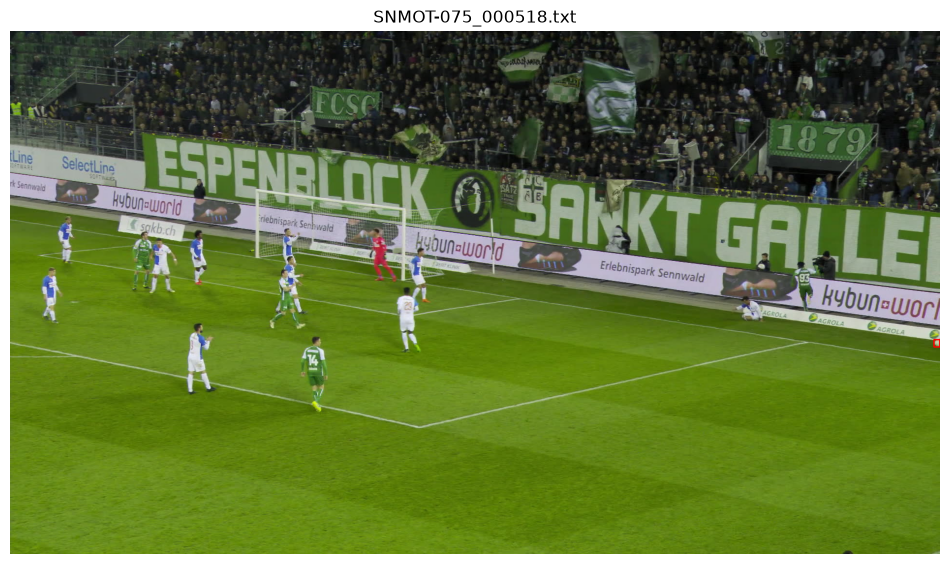

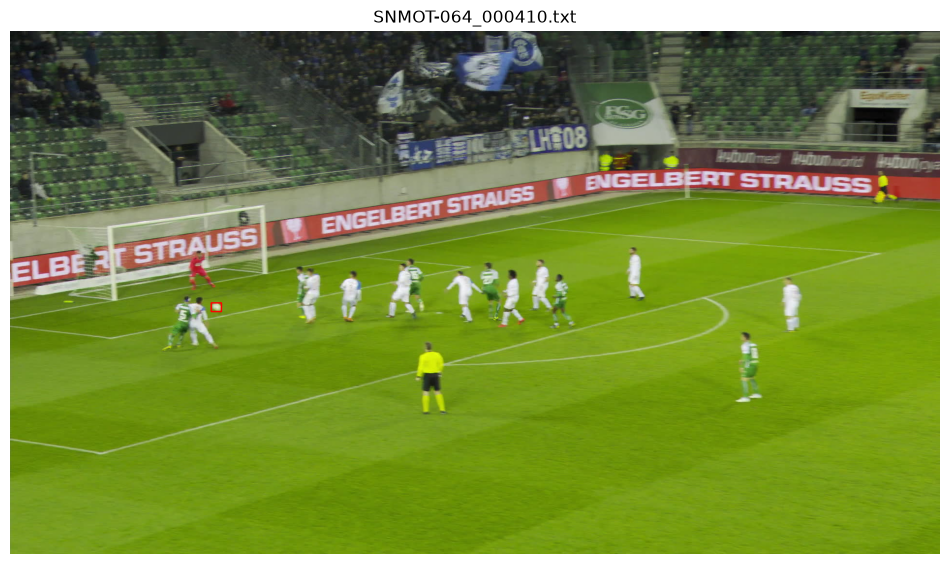

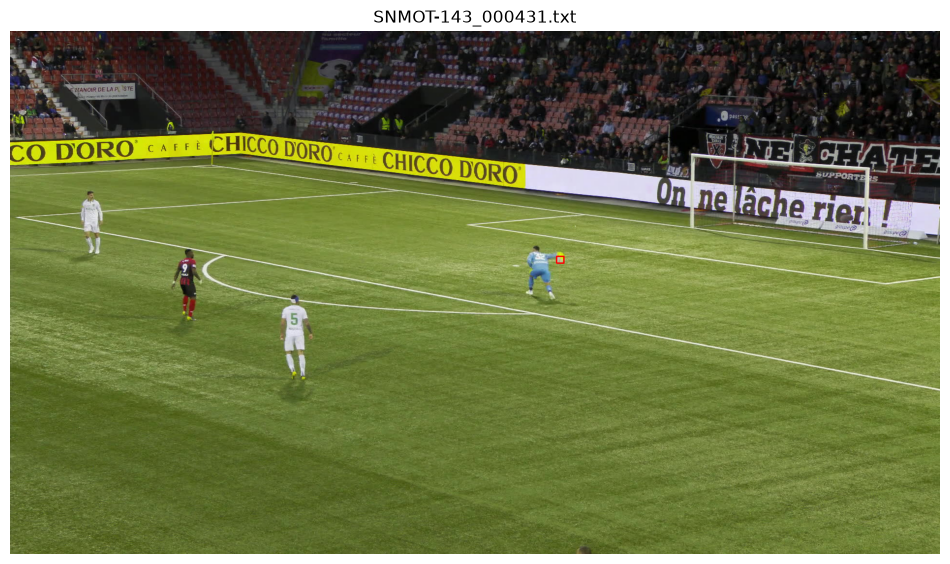

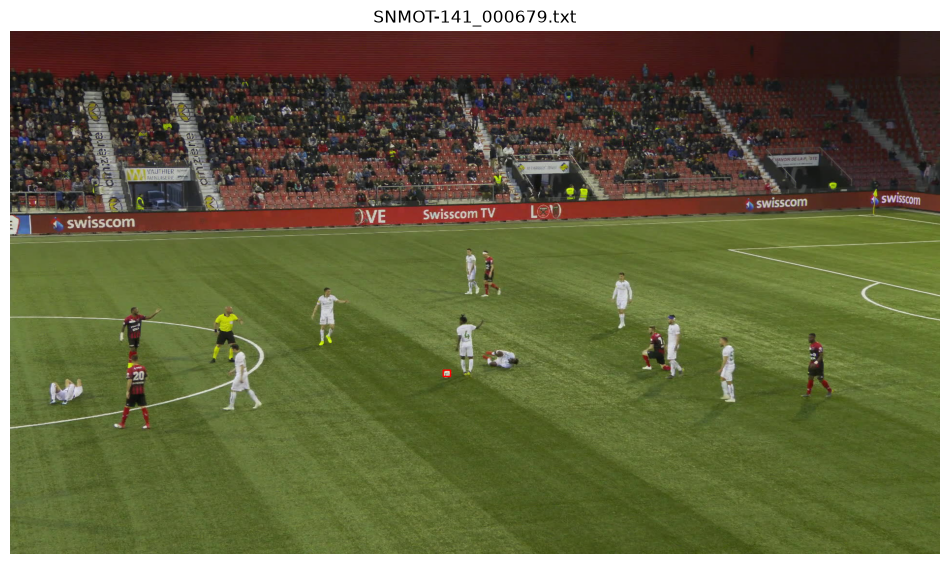

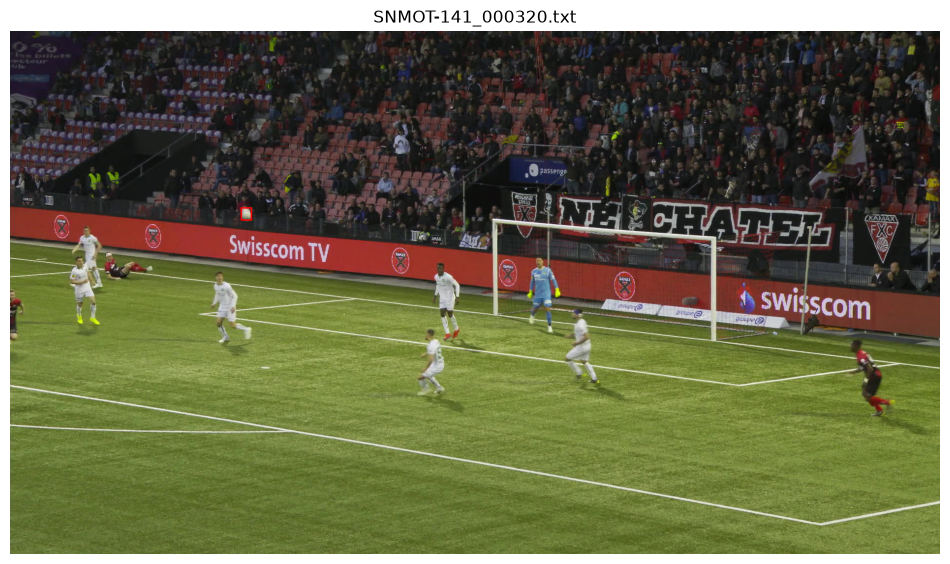

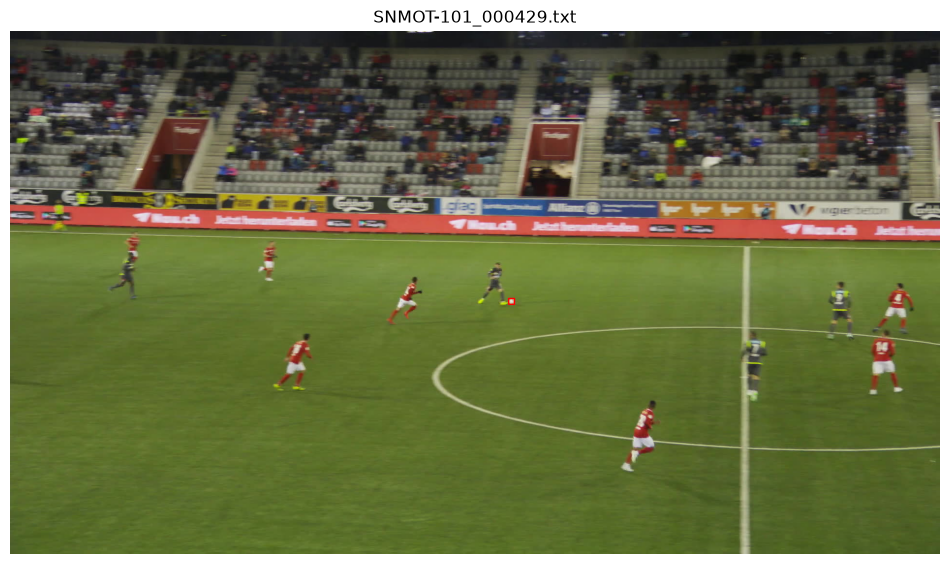

In [5]:
# =========================================================
# Cell 5 — Random visual verification of YOLO labels
# =========================================================

import random
import cv2
import matplotlib.pyplot as plt

random.seed(42)

# Select a few non-empty labels from validation set
label_dir = OUTPUT_ROOT / "labels" / "val"
image_dir = OUTPUT_ROOT / "images" / "val"

non_empty_labels = []

for label_path in label_dir.glob("*.txt"):
    if label_path.stat().st_size > 0:
        non_empty_labels.append(label_path)

samples = random.sample(
    non_empty_labels,
    min(6, len(non_empty_labels))
)

print("Selected samples:")
for p in samples:
    print(" ", p.name)

# Display samples
for label_path in samples:
    
    image_path = image_dir / f"{label_path.stem}.jpg"
    
    image = cv2.imread(str(image_path))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    
    h, w = image.shape[:2]
    
    with label_path.open() as f:
        for line in f:
            
            parts = line.split()
            
            if len(parts) != 5:
                continue
            
            cls, cx, cy, bw, bh = map(float, parts)
            
            # YOLO normalized → pixel coordinates
            cx *= w
            cy *= h
            bw *= w
            bh *= h
            
            x1 = int(cx - bw / 2)
            y1 = int(cy - bh / 2)
            x2 = int(cx + bw / 2)
            y2 = int(cy + bh / 2)
            
            cv2.rectangle(
                image,
                (x1, y1),
                (x2, y2),
                (255, 0, 0),
                2
            )
    
    plt.figure(figsize=(12, 7))
    plt.imshow(image)
    plt.title(label_path.name)
    plt.axis("off")
    plt.show()

Available samples by size:
  very_small  : 1,269
  small       : 6,580
  medium      : 2,269
  large       : 146

Selected samples:
  very_small  : SNMOT-064_000229.txt
  small       : SNMOT-075_000014.txt
  medium      : SNMOT-141_000559.txt
  large       : SNMOT-068_000716.txt


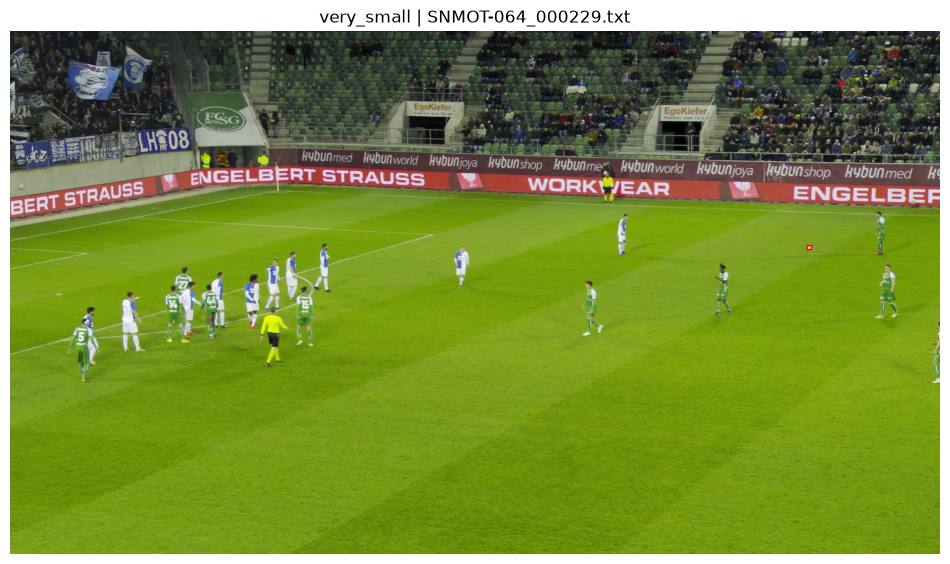

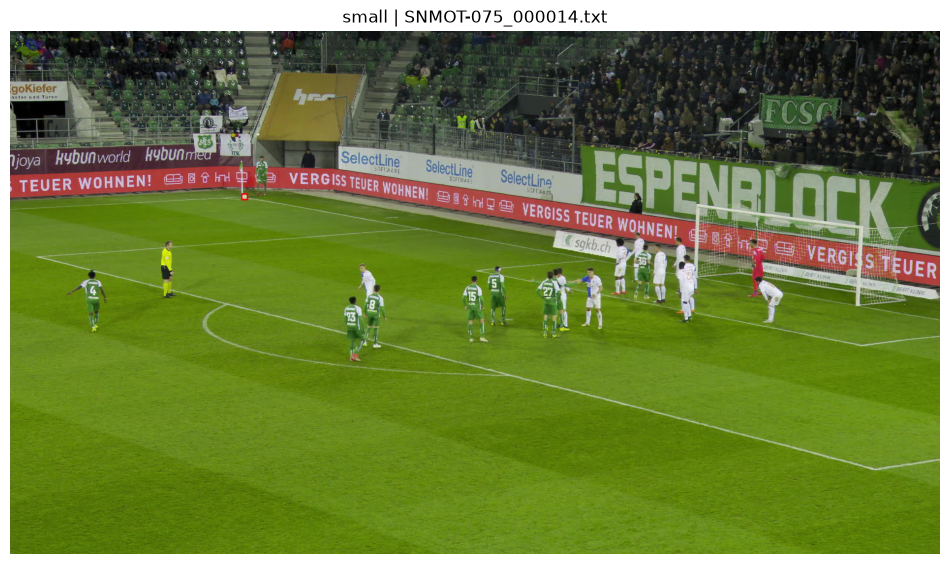

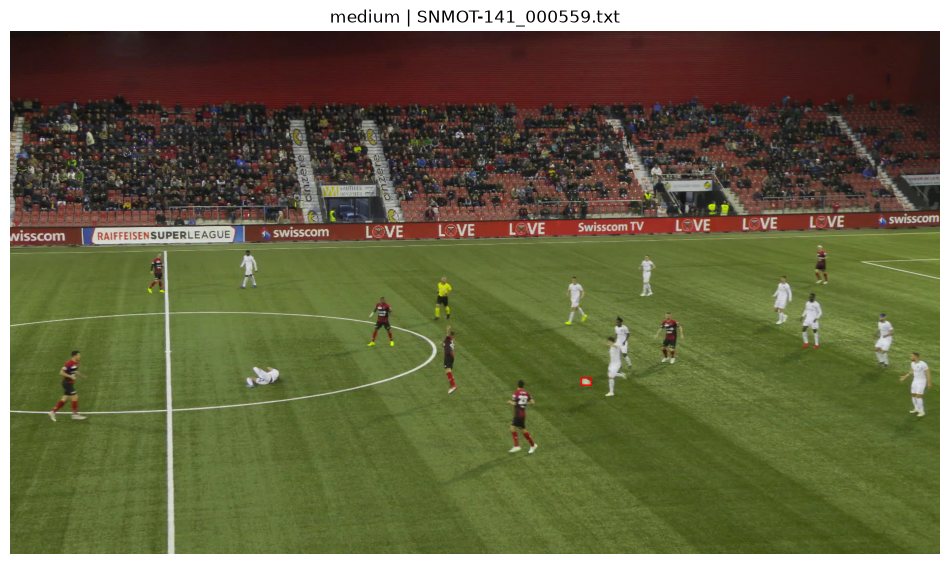

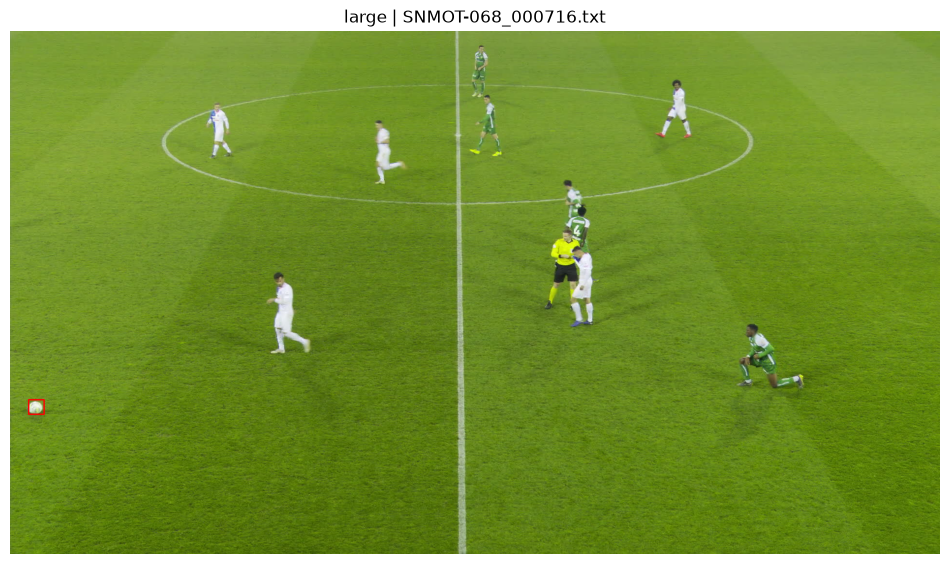

In [6]:
# =========================================================
# Cell 6 — Visual verification across ball-size ranges
# =========================================================

import cv2
import matplotlib.pyplot as plt
import random

random.seed(42)

label_dir = OUTPUT_ROOT / "labels" / "val"
image_dir = OUTPUT_ROOT / "images" / "val"

# ---------------------------------------------------------
# Collect non-empty labels with ball area information
# ---------------------------------------------------------

samples_by_size = {
    "very_small": [],
    "small": [],
    "medium": [],
    "large": [],
}

for label_path in label_dir.glob("*.txt"):

    if label_path.stat().st_size == 0:
        continue

    areas = []

    with label_path.open() as f:
        for line in f:

            parts = line.split()

            if len(parts) != 5:
                continue

            _, cx, cy, bw, bh = map(float, parts)

            # Normalized bbox area
            area = bw * bh
            areas.append(area)

    if not areas:
        continue

    # Use the largest ball annotation in this frame
    area = max(areas)

    if area < 0.00005:
        category = "very_small"
    elif area < 0.00015:
        category = "small"
    elif area < 0.00040:
        category = "medium"
    else:
        category = "large"

    samples_by_size[category].append(label_path)


# ---------------------------------------------------------
# Select one random sample from each category
# ---------------------------------------------------------

selected = []

for category in [
    "very_small",
    "small",
    "medium",
    "large"
]:

    candidates = samples_by_size[category]

    if candidates:
        selected.append(
            (category, random.choice(candidates))
        )


print("Available samples by size:")
for category, candidates in samples_by_size.items():
    print(f"  {category:12s}: {len(candidates):,}")

print()
print("Selected samples:")

for category, label_path in selected:
    print(f"  {category:12s}: {label_path.name}")


# ---------------------------------------------------------
# Display selected images
# ---------------------------------------------------------

for category, label_path in selected:

    image_path = image_dir / f"{label_path.stem}.jpg"

    image = cv2.imread(str(image_path))

    if image is None:
        print(f"Could not read: {image_path}")
        continue

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    h, w = image.shape[:2]

    with label_path.open() as f:

        for line in f:

            parts = line.split()

            if len(parts) != 5:
                continue

            cls, cx, cy, bw, bh = map(float, parts)

            # YOLO normalized → pixel coordinates
            cx *= w
            cy *= h
            bw *= w
            bh *= h

            x1 = int(cx - bw / 2)
            y1 = int(cy - bh / 2)
            x2 = int(cx + bw / 2)
            y2 = int(cy + bh / 2)

            cv2.rectangle(
                image,
                (x1, y1),
                (x2, y2),
                (255, 0, 0),
                2
            )

    plt.figure(figsize=(12, 7))
    plt.imshow(image)
    plt.title(
        f"{category} | {label_path.name}"
    )
    plt.axis("off")
    plt.show()

In [7]:
# =========================================================
# Cell 7 — Create final dataset configuration + manifest
# =========================================================

import json
from datetime import datetime

# ---------------------------------------------------------
# Dataset configuration
# ---------------------------------------------------------

DATA_YAML = OUTPUT_ROOT / "data.yaml"
MANIFEST_PATH = OUTPUT_ROOT / "dataset_manifest.json"

dataset_yaml = f"""path: "{OUTPUT_ROOT.as_posix()}"
train: images/train
val: images/val
test: images/test

names:
  0: ball
"""

DATA_YAML.write_text(
    dataset_yaml,
    encoding="utf-8"
)

# ---------------------------------------------------------
# Collect final dataset statistics
# ---------------------------------------------------------

split_stats = {}

for split in ["train", "val", "test"]:

    image_dir = OUTPUT_ROOT / "images" / split
    label_dir = OUTPUT_ROOT / "labels" / split

    images = list(image_dir.glob("*.jpg"))
    labels = list(label_dir.glob("*.txt"))

    ball_boxes = 0
    empty_labels = 0

    for label_path in labels:

        lines = [
            line.strip()
            for line in label_path.read_text().splitlines()
            if line.strip()
        ]

        if not lines:
            empty_labels += 1
        else:
            ball_boxes += len(lines)

    sequences = sorted({
        p.stem.rsplit("_", 1)[0]
        for p in images
    })

    split_stats[split] = {
        "sequences": len(sequences),
        "sequence_names": sequences,
        "images": len(images),
        "labels": len(labels),
        "ball_boxes": ball_boxes,
        "empty_labels": empty_labels
    }


# ---------------------------------------------------------
# Final manifest
# ---------------------------------------------------------

manifest = {
    "dataset": {
        "name": "AthletiQ SoccerNet Football Ball Detection",
        "source": "SoccerNet Tracking",
        "task": "object_detection",
        "class_count": 1,
        "classes": {
            "0": "ball"
        }
    },

    "conversion": {
        "source_format": "MOT",
        "target_format": "YOLO Detection",
        "ball_track_ids_used": True,
        "track_ids_discarded_for_detection": True,
        "original_annotations_modified": False
    },

    "split": {
        "seed": 42,
        "train_sequences": 74,
        "val_sequences": 15,
        "test_sequences": 17,
        "total_sequences": 106
    },

    "statistics": split_stats,

    "totals": {
        "sequences": sum(
            x["sequences"] for x in split_stats.values()
        ),
        "images": sum(
            x["images"] for x in split_stats.values()
        ),
        "labels": sum(
            x["labels"] for x in split_stats.values()
        ),
        "ball_boxes": sum(
            x["ball_boxes"] for x in split_stats.values()
        ),
        "empty_labels": sum(
            x["empty_labels"] for x in split_stats.values()
        )
    },

    "validation": {
        "expected_images": 79500,
        "expected_ball_boxes": 75060,
        "invalid_lines": 0,
        "missing_labels": 0,
        "orphan_labels": 0
    },

    "created_at": datetime.now().isoformat()
}

MANIFEST_PATH.write_text(
    json.dumps(manifest, indent=2),
    encoding="utf-8"
)

# ---------------------------------------------------------
# Display result
# ---------------------------------------------------------

print("=" * 60)
print("FINAL DATASET CONFIGURATION CREATED")
print("=" * 60)

print()
print("data.yaml:")
print(DATA_YAML)

print()
print("manifest:")
print(MANIFEST_PATH)

print()
print("=" * 60)
print("DATASET SUMMARY")
print("=" * 60)

for split, stats in split_stats.items():

    print(
        f"{split.upper():5s} | "
        f"{stats['sequences']:2d} sequences | "
        f"{stats['images']:6,} images | "
        f"{stats['labels']:6,} labels | "
        f"{stats['ball_boxes']:6,} boxes"
    )

print()
print(
    f"TOTAL  | "
    f"{manifest['totals']['sequences']:3d} sequences | "
    f"{manifest['totals']['images']:6,} images | "
    f"{manifest['totals']['labels']:6,} labels | "
    f"{manifest['totals']['ball_boxes']:6,} boxes"
)

print()
print("✅ data.yaml created")
print("✅ dataset_manifest.json created")

FINAL DATASET CONFIGURATION CREATED

data.yaml:
/mnt/d/My Projects/AthletiQ/AthletiQ/datasets/football/processed/soccernet_ball_yolo/data.yaml

manifest:
/mnt/d/My Projects/AthletiQ/AthletiQ/datasets/football/processed/soccernet_ball_yolo/dataset_manifest.json

DATASET SUMMARY
TRAIN | 74 sequences | 55,500 images | 55,500 labels | 52,580 boxes
VAL   | 15 sequences | 11,250 images | 11,250 labels | 10,636 boxes
TEST  | 17 sequences | 12,750 images | 12,750 labels | 11,844 boxes

TOTAL  | 106 sequences | 79,500 images | 79,500 labels | 75,060 boxes

✅ data.yaml created
✅ dataset_manifest.json created


In [8]:
# =========================================================
# Cell 8 — Final configuration verification
# =========================================================

import yaml
import json

# ---------------------------------------------------------
# Load data.yaml
# ---------------------------------------------------------

with DATA_YAML.open("r", encoding="utf-8") as f:
    data_config = yaml.safe_load(f)

# ---------------------------------------------------------
# Load manifest
# ---------------------------------------------------------

with MANIFEST_PATH.open("r", encoding="utf-8") as f:
    manifest = json.load(f)

print("=" * 60)
print("DATA.YAML")
print("=" * 60)

print("Path  :", data_config["path"])
print("Train :", data_config["train"])
print("Val   :", data_config["val"])
print("Test  :", data_config["test"])
print("Names :", data_config["names"])

print()
print("=" * 60)
print("MANIFEST")
print("=" * 60)

print(
    "Dataset :",
    manifest["dataset"]["name"]
)

print(
    "Task    :",
    manifest["dataset"]["task"]
)

print(
    "Classes :",
    manifest["dataset"]["classes"]
)

print()
print("Split:")
print(
    "  Train:",
    manifest["split"]["train_sequences"]
)
print(
    "  Val  :",
    manifest["split"]["val_sequences"]
)
print(
    "  Test :",
    manifest["split"]["test_sequences"]
)

print()
print("Totals:")
print(
    "  Sequences:",
    f"{manifest['totals']['sequences']:,}"
)
print(
    "  Images   :",
    f"{manifest['totals']['images']:,}"
)
print(
    "  Labels   :",
    f"{manifest['totals']['labels']:,}"
)
print(
    "  Boxes    :",
    f"{manifest['totals']['ball_boxes']:,}"
)

print()
print("=" * 60)
print("CONFIGURATION CHECK")
print("=" * 60)

checks = [
    data_config["names"] == {0: "ball"},
    manifest["totals"]["sequences"] == 106,
    manifest["totals"]["images"] == 79500,
    manifest["totals"]["labels"] == 79500,
    manifest["totals"]["ball_boxes"] == 75060,
]

if all(checks):
    print("✅ FINAL CONFIGURATION VERIFIED")
else:
    print("❌ CONFIGURATION CHECK FAILED")

DATA.YAML
Path  : /mnt/d/My Projects/AthletiQ/AthletiQ/datasets/football/processed/soccernet_ball_yolo
Train : images/train
Val   : images/val
Test  : images/test
Names : {0: 'ball'}

MANIFEST
Dataset : AthletiQ SoccerNet Football Ball Detection
Task    : object_detection
Classes : {'0': 'ball'}

Split:
  Train: 74
  Val  : 15
  Test : 17

Totals:
  Sequences: 106
  Images   : 79,500
  Labels   : 79,500
  Boxes    : 75,060

CONFIGURATION CHECK
✅ FINAL CONFIGURATION VERIFIED


In [9]:
# =========================================================
# Cell 9 — Remove temporary conversion test
# =========================================================

import shutil

TEMP_TEST_ROOT = (
    PROJECT_ROOT
    / "datasets"
    / "football"
    / "processed"
    / "soccernet_ball_test"
)

print("=" * 60)
print("TEMPORARY TEST DATASET CLEANUP")
print("=" * 60)

if TEMP_TEST_ROOT.exists():

    print("Found:")
    print(TEMP_TEST_ROOT)

    shutil.rmtree(TEMP_TEST_ROOT)

    print()
    print("✅ Temporary test dataset removed")

else:

    print("Temporary test dataset not found.")
    print("✅ Nothing to remove")

print()
print("Production dataset remains untouched:")
print(OUTPUT_ROOT)

TEMPORARY TEST DATASET CLEANUP
Found:
/mnt/d/My Projects/AthletiQ/AthletiQ/datasets/football/processed/soccernet_ball_test

✅ Temporary test dataset removed

Production dataset remains untouched:
/mnt/d/My Projects/AthletiQ/AthletiQ/datasets/football/processed/soccernet_ball_yolo


In [10]:
# =========================================================
# Cell 10 — Final filesystem audit
# =========================================================

print("=" * 60)
print("FINAL SOCCERNET BALL DATASET AUDIT")
print("=" * 60)

expected = {
    "train": (55500, 55500),
    "val":   (11250, 11250),
    "test":  (12750, 12750),
}

all_passed = True

for split, (expected_images, expected_labels) in expected.items():

    image_dir = OUTPUT_ROOT / "images" / split
    label_dir = OUTPUT_ROOT / "labels" / split

    image_count = len(list(image_dir.glob("*.jpg")))
    label_count = len(list(label_dir.glob("*.txt")))

    images_ok = image_count == expected_images
    labels_ok = label_count == expected_labels
    pairing_ok = image_count == label_count

    passed = images_ok and labels_ok and pairing_ok

    if not passed:
        all_passed = False

    print()
    print(split.upper())
    print("-" * 60)
    print(
        f"Images : {image_count:,} "
        f"(expected {expected_images:,}) "
        f"{'✅' if images_ok else '❌'}"
    )
    print(
        f"Labels : {label_count:,} "
        f"(expected {expected_labels:,}) "
        f"{'✅' if labels_ok else '❌'}"
    )
    print(
        f"Pairing: {'✅' if pairing_ok else '❌'}"
    )

# ---------------------------------------------------------
# Required files
# ---------------------------------------------------------

required_files = [
    DATA_YAML,
    MANIFEST_PATH,
]

print()
print("=" * 60)
print("REQUIRED FILES")
print("=" * 60)

for path in required_files:

    exists = path.exists()

    print(
        f"{path.name:25s} "
        f"{'✅' if exists else '❌'}"
    )

    if not exists:
        all_passed = False

# ---------------------------------------------------------
# Temporary directory check
# ---------------------------------------------------------

temp_dir = (
    PROJECT_ROOT
    / "datasets"
    / "football"
    / "processed"
    / "soccernet_ball_test"
)

print()
print("=" * 60)
print("TEMPORARY DATA")
print("=" * 60)

if temp_dir.exists():
    print("❌ Temporary test directory still exists")
    all_passed = False
else:
    print("✅ Temporary test directory removed")

# ---------------------------------------------------------
# Final result
# ---------------------------------------------------------

print()
print("=" * 60)

if all_passed:
    print("✅ FINAL DATASET AUDIT PASSED")
    print("✅ LOCAL DATA PREPARATION COMPLETE")
else:
    print("❌ FINAL AUDIT FAILED — DO NOT MOVE TO COLAB")

print("=" * 60)

FINAL SOCCERNET BALL DATASET AUDIT

TRAIN
------------------------------------------------------------
Images : 55,500 (expected 55,500) ✅
Labels : 55,500 (expected 55,500) ✅
Pairing: ✅

VAL
------------------------------------------------------------
Images : 11,250 (expected 11,250) ✅
Labels : 11,250 (expected 11,250) ✅
Pairing: ✅

TEST
------------------------------------------------------------
Images : 12,750 (expected 12,750) ✅
Labels : 12,750 (expected 12,750) ✅
Pairing: ✅

REQUIRED FILES
data.yaml                 ✅
dataset_manifest.json     ✅

TEMPORARY DATA
✅ Temporary test directory removed

✅ FINAL DATASET AUDIT PASSED
✅ LOCAL DATA PREPARATION COMPLETE
